# Exploración y preparación inicial — Grupo 6 UTS

**Proyecto:** Consumo energético.  
**Integrantes:** Wendy Yolanny Jaimes Lugo, Jonathan David Quintero Villamizar y Javier Andrés Socha Maldonado.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# El CSV no está en el repo: se descarga desde UCI (id 374), igual que en el notebook 01
ds = fetch_ucirepo(id=374)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)
df['date'] = pd.to_datetime(df['date'].astype(str).str.replace(' ', ''), format='%Y-%m-%d%H:%M:%S')
df = df.sort_values('date').reset_index(drop=True)
print('Dimensiones:', df.shape)
display(df.head())


Dimensiones: (19735, 29)


,date,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Appliances
0,2016-01-11 17:00:00,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,60
1,2016-01-11 17:10:00,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,60
2,2016-01-11 17:20:00,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,50
3,2016-01-11 17:30:00,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390,50
4,2016-01-11 17:40:00,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,60


In [2]:
print('Nulos totales:', df.isna().sum().sum())
print('Filas duplicadas:', df.duplicated().sum())
print('Fechas:', df['date'].min(), 'a', df['date'].max())
print('Orden cronológico:', df['date'].is_monotonic_increasing)
print(df['date'].diff().value_counts().head())
display(df.describe().T)


Nulos totales: 0
Filas duplicadas: 0
Fechas: 2016-01-11 17:00:00 a 2016-05-27 18:00:00
Orden cronológico: True
date
0 days 00:10:00    19734
Name: count, dtype: int64


,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884
RH_4,19735.0,39.026904,27.66,35.53,38.4,42.156667,51.09,4.341321


count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64
Límites IQR: -25.0 175.0
Fuera de límites: 2138


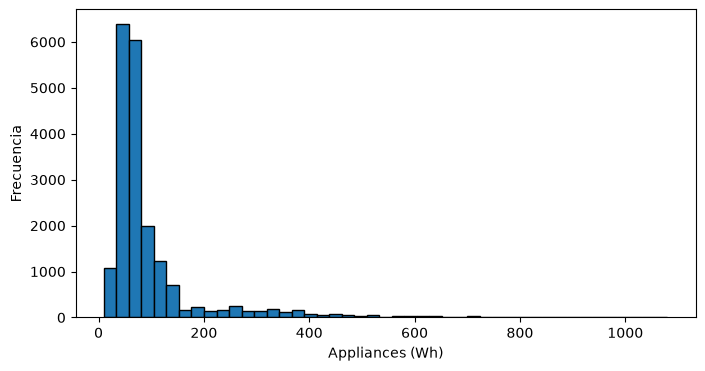

In [3]:
print(df['Appliances'].describe())
q1, q3 = df['Appliances'].quantile([0.25, 0.75]); iqr = q3-q1
print('Límites IQR:', q1-1.5*iqr, q3+1.5*iqr)
print('Fuera de límites:', ((df['Appliances'] < q1-1.5*iqr) | (df['Appliances'] > q3+1.5*iqr)).sum())
plt.figure(figsize=(8,4)); plt.hist(df['Appliances'], bins=45, edgecolor='black')
plt.xlabel('Appliances (Wh)'); plt.ylabel('Frecuencia'); plt.show()


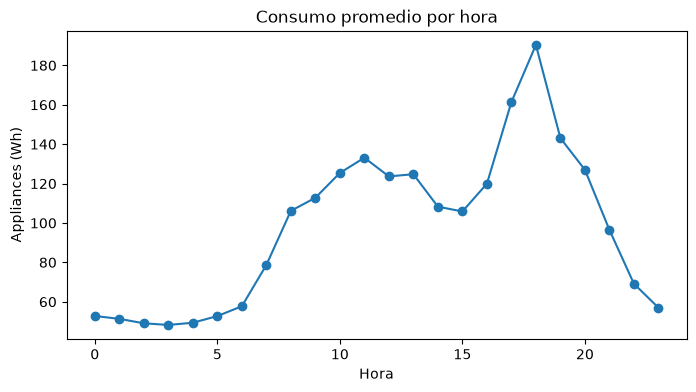

In [4]:
hourly = df.assign(hour=df['date'].dt.hour).groupby('hour')['Appliances'].mean()
ax = hourly.plot(marker='o', figsize=(8,4), title='Consumo promedio por hora')
ax.set_xlabel('Hora'); ax.set_ylabel('Appliances (Wh)'); plt.show()


lights       0.197278
T2           0.120073
T6           0.117638
T_out        0.099155
Windspeed    0.087122
RH_1         0.086031
T3           0.085060
T1           0.055447
T4           0.040281
T8           0.039572
RH_3         0.036292
T7           0.025801
Name: Appliances, dtype: float64

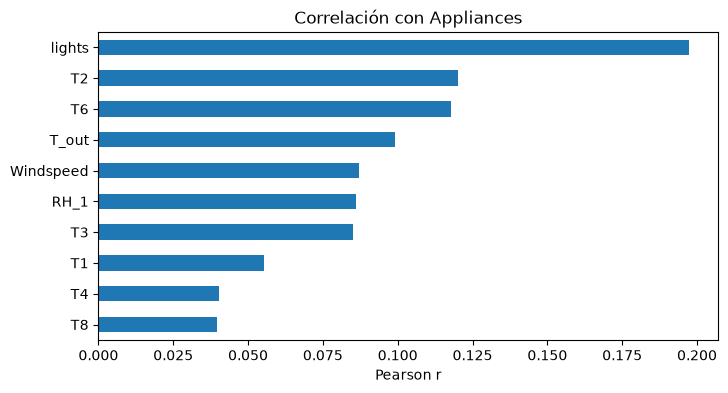

In [5]:
corr = df.select_dtypes('number').corr()['Appliances'].drop('Appliances').sort_values(ascending=False)
display(corr.head(12))
corr.head(10).sort_values().plot(kind='barh', figsize=(8,4), title='Correlación con Appliances')
plt.xlabel('Pearson r'); plt.show()


In [6]:
split = int(len(df) * 0.80)
train = df.iloc[:split].copy(); test = df.iloc[split:].copy()
print('Entrenamiento:', train['date'].min(), 'a', train['date'].max(), len(train))
print('Prueba:', test['date'].min(), 'a', test['date'].max(), len(test))
for part in (train, test):
    part['hour'] = part['date'].dt.hour
    part['dayofweek'] = part['date'].dt.day_of_week
    part['is_weekend'] = (part['dayofweek'] >= 5).astype(int)
# Definir el escenario de predicción antes de decidir si 'lights' está disponible.
# Excluir date cruda y evaluar rv1/rv2 como variables aleatorias no predictivas.


Entrenamiento: 2016-01-11 17:00:00 a 2016-04-30 08:10:00 15788
Prueba: 2016-04-30 08:20:00 a 2016-05-27 18:00:00 3947
